In [3]:
import torch 
import matplotlib.pyplot as plt
import numpy as np 

In [4]:
print(f"pytorch version : {torch.__version__}")

pytorch version : 2.9.1+cu130


In [5]:
torch.cuda.is_available()  # -> to check whether we have access to the GPU 

True

### Import the necessary modules

In [6]:
from torchvision import datasets
from torchvision.transforms import ToTensor  # -> this is used to convert images into tensors 
import torchmetrics # -> opensource library for pytorch (providing helper functions for torchmetrices)
from torch import nn
from torch.utils.data import DataLoader

## Download the CIFAR_10 Dataset

In [7]:
from datasets import load_dataset

In [8]:
hf_dataset = load_dataset("uoft-cs/cifar10")
hf_dataset

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})

In [9]:
hf_dataset.column_names

{'train': ['img', 'label'], 'test': ['img', 'label']}

## Analysing the data

In [10]:
train_data = hf_dataset['train'].with_format('torch')
test_data = hf_dataset['test'].with_format('torch')

In [11]:
single_train_data = train_data[0]

### Look the shape of the tensors 

In [12]:
single_train_data

{'img': tensor([[[178, 178, 178,  ..., 170, 168, 165],
          [180, 179, 180,  ..., 173, 171, 168],
          [177, 177, 178,  ..., 171, 169, 167],
          ...,
          [112, 113, 114,  ..., 100,  98, 101],
          [112, 112, 113,  ..., 102, 102, 102],
          [103, 100, 103,  ...,  92,  93,  91]],
 
         [[176, 176, 176,  ..., 168, 166, 163],
          [178, 177, 178,  ..., 171, 169, 166],
          [175, 175, 176,  ..., 169, 167, 165],
          ...,
          [107, 109, 110,  ...,  97,  94,  95],
          [102, 103, 103,  ...,  95,  93,  92],
          [ 96,  93,  95,  ...,  84,  86,  84]],
 
         [[189, 189, 189,  ..., 180, 177, 174],
          [191, 190, 191,  ..., 182, 180, 177],
          [188, 188, 189,  ..., 180, 178, 176],
          ...,
          [107, 108, 110,  ...,  94,  93,  95],
          [101, 102, 103,  ...,  93,  91,  91],
          [ 92,  90,  94,  ...,  80,  80,  77]]], dtype=torch.uint8),
 'label': tensor(0)}

In [13]:
print(f"The lenght of training data : {len(train_data['img'])}")
print(f"The length of testing data : {len(test_data['img'])}")

The lenght of training data : 50000
The length of testing data : 10000


In [14]:
single_train_data['img'].shape

torch.Size([3, 32, 32])

In [15]:
single_train_data['img'].dtype

torch.uint8

In [16]:
train_loader = DataLoader(train_data,batch_size=32,shuffle=True,drop_last=True)

In [17]:
test_loader = DataLoader(test_data,batch_size=32,shuffle=True,drop_last=True)

In [18]:
next(iter(train_loader))['img'].dtype

torch.uint8

## Display the image 

In [19]:
classes = train_data.features['label'].names
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

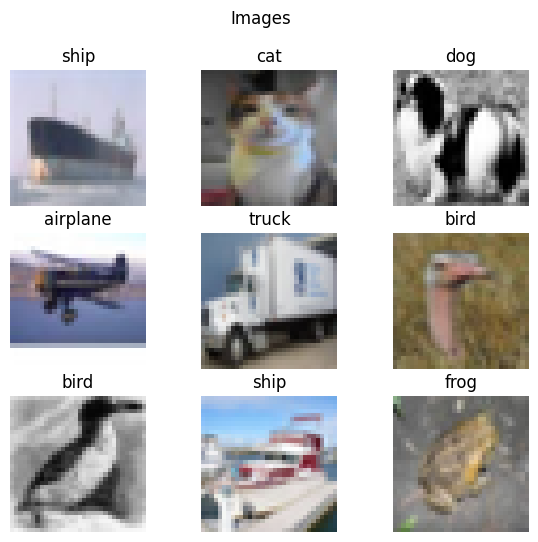

In [20]:
plt.figure(figsize=(7,6))
rows , cols = 3, 3
plt.suptitle("Images")
for i in range(1,10):
    random_value = torch.randint(0,len(train_data),(1,)).item()
    image_tensor = train_data['img'][random_value]
    # change the dimension -> color channel at last 
    image_tensor = image_tensor.permute(1,2,0)
    # plot the image 
    label = classes[train_data['label'][random_value].item()]
    plt.subplot(rows,cols,i)
    plt.imshow(image_tensor)
    plt.title(label)
    plt.axis('off')

plt.show()
    

## Creating CNN Model

In [21]:
class CIFAR_MODEL_V0(nn.Module):
    def __init__(self,input_shape:int,hidden_units:int, output_shape:int):
        super().__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=3,out_channels=10,padding=1,stride=1,kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(in_channels=10,out_channels=10,padding=1,stride=1,kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=10,out_channels=10,padding=1,stride=1,kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(in_channels=10,out_channels=10,padding=1,stride=1,kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=640,out_features=len(classes))
        )

    def forward(self,x):
        layer1 = self.layer1(x)
        layer2 = self.layer2(layer1)
        classifier = self.classifier(layer2)
        return classifier
        

In [22]:
model_0 = CIFAR_MODEL_V0(3,10,10)

In [23]:
list(model_0.parameters())

[Parameter containing:
 tensor([[[[-0.0744, -0.0003,  0.0404],
           [-0.1359, -0.0644, -0.1375],
           [-0.1253,  0.0385, -0.0114]],
 
          [[-0.1729, -0.0387, -0.1293],
           [ 0.1183,  0.0487,  0.0688],
           [ 0.0523, -0.1775, -0.1363]],
 
          [[ 0.0209, -0.0096, -0.0063],
           [-0.0132,  0.0732, -0.0053],
           [-0.0317, -0.1255, -0.0841]]],
 
 
         [[[ 0.1406,  0.1845, -0.0011],
           [-0.1187, -0.1142,  0.1421],
           [ 0.1088,  0.1437, -0.0179]],
 
          [[-0.1563, -0.1693, -0.1445],
           [-0.1469, -0.0799,  0.0018],
           [-0.1230, -0.0829,  0.1667]],
 
          [[ 0.0540, -0.1410, -0.0292],
           [-0.0633, -0.0490, -0.0085],
           [ 0.0204, -0.0060,  0.0033]]],
 
 
         [[[-0.0469,  0.0822, -0.1669],
           [-0.0213,  0.0971,  0.1659],
           [ 0.1867,  0.0268,  0.1167]],
 
          [[-0.1635,  0.0246, -0.1340],
           [ 0.1644,  0.1400,  0.0252],
           [-0.1618, -0.0429, 

In [24]:
from torchmetrics import Accuracy
from tqdm import tqdm

### Training and Testing the model 

In [31]:
def train_test_model(model,loss_fn,optimizer,device,train_data,test_data,epochs):
    
    accuracy = Accuracy(task='multiclass',num_classes=10).to(device)

    # train and test the model 
    for epoch in range(epochs):
        total_train_loss , total_test_loss, total_train_acc, total_test_acc = 0,0,0,0
        # set the model to train mode 
        model.train()
        # train the model in batchwise
        for batch in tqdm(train_data,desc=f"Epoch {epoch+1}/{epochs}"):
            # convert the input into respected format type and store in correct device ('cuda' or 'cpu')
            image_tensor = (batch['img'].float()/255.0).to(device)
            label_tensor = batch['label'].to(device)
            
            # do the forward pass 
            y_pred = model.forward(image_tensor)

            # calculate the training accuracy 
            train_acc = accuracy(y_pred,label_tensor)

            # calculate the loss 
            y_pred_loss = loss_fn(y_pred,label_tensor)

            # set the optimizer zero grad
            optimizer.zero_grad()

            # do the loss backward
            y_pred_loss.backward()

            # optimizer step 
            optimizer.step()

            total_train_acc += train_acc 
            total_train_loss += y_pred_loss

        # calculate the testing loss 
        model.eval()
        with torch.inference_mode():
            for batch in test_data : 
                image_tensor = (batch['img'].float()/255.0).to(device)
                label_tensor = batch['label'].to(device)

                y_pred_test = model.forward(image_tensor)
                
                test_acc = accuracy(y_pred_test,label_tensor)
                y_pred_test_loss = loss_fn(y_pred_test,label_tensor)
                total_test_acc += test_acc
                total_test_loss += y_pred_test_loss
                
            total_test_acc /= len(test_data)
            total_test_loss /= len(test_data)
        total_train_acc /= len(train_data)
        total_train_loss /= len(train_data)

        # print all the details 
        print(f"EPOCH: {epoch} | Train Acc: {total_train_acc} | Test Acc: {total_test_acc} | Train Loss: {total_train_loss} | Test Loss: {total_test_loss}")

                

In [32]:
# pickup the loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(),lr=0.001)

In [34]:
train_test_model(model_0,loss_fn,optimizer,'cpu',train_loader,test_loader,100)

Epoch 1/100: 100%|███████████████████████████████████████████████████████| 1562/1562 [00:27<00:00, 56.91it/s]


EPOCH: 0 | Train Acc: 0.683918833732605 | Test Acc: 0.6484375 | Train Loss: 0.9013413190841675 | Test Loss: 0.9970685243606567


Epoch 2/100: 100%|███████████████████████████████████████████████████████| 1562/1562 [00:29<00:00, 52.76it/s]


EPOCH: 1 | Train Acc: 0.6867997646331787 | Test Acc: 0.6570512652397156 | Train Loss: 0.8942534923553467 | Test Loss: 0.9774211049079895


Epoch 3/100: 100%|███████████████████████████████████████████████████████| 1562/1562 [00:29<00:00, 52.09it/s]


EPOCH: 2 | Train Acc: 0.6883202791213989 | Test Acc: 0.6521434187889099 | Train Loss: 0.8909957408905029 | Test Loss: 0.9916699528694153


... (190 outputs left out)

Epoch 99/100: 100%|██████████████████████████████████████████████████████| 1562/1562 [00:25<00:00, 61.70it/s]


EPOCH: 98 | Train Acc: 0.7448183298110962 | Test Acc: 0.6744791865348816 | Train Loss: 0.7297295331954956 | Test Loss: 0.9583243131637573


Epoch 100/100: 100%|█████████████████████████████████████████████████████| 1562/1562 [00:24<00:00, 64.27it/s]


EPOCH: 99 | Train Acc: 0.7425376176834106 | Test Acc: 0.6647636294364929 | Train Loss: 0.7291193604469299 | Test Loss: 1.0185937881469727


## Visulaising the model's output

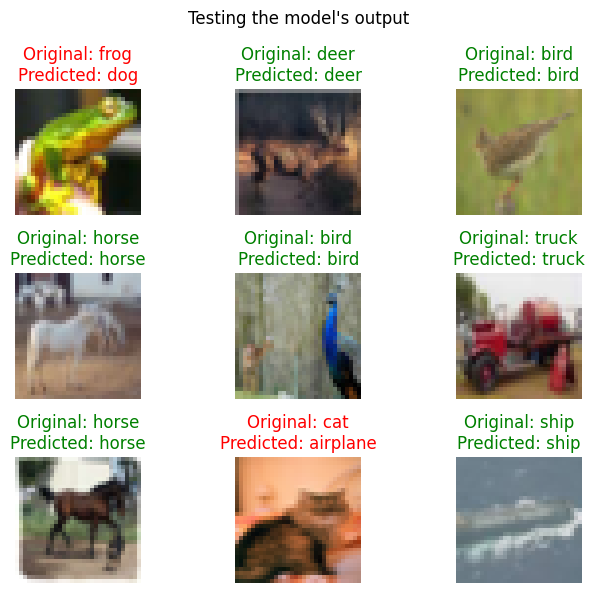

In [73]:
plt.figure(figsize=(7,6))
plt.suptitle("Testing the model's output")
rows, cols = 3,3 
for i in range(1,10):
    rnd_index = torch.randint(1,len(test_data),(1,)).item()
    test_image = test_data[rnd_index]['img'].float() / 255 
    test_label = test_data[rnd_index]['label'].item()   #  -> it gives in int type output ex : 0 1 2 
    predicted_value = model_0(test_image.unsqueeze(dim=0)) 
    
    sm = predicted_value.softmax(dim=1)
    predicted_label_value = torch.argmax(sm,dim=1).item()
    
    predicted_label = classes[predicted_label_value]
    original_label = classes[test_label]

    title_color = 'green' if predicted_label == original_label else 'red'

    plt.subplot(rows,cols,i)
    plt.title(f"Original: {original_label}\nPredicted: {predicted_label}",color=title_color)
    plt.imshow(test_image.permute(1,2,0))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [87]:
from torchmetrics import ConfusionMatrix

def test(model,test_loader,device):
    confmat = ConfusionMatrix(task='multiclass',num_classes=10,normalize="true").to(device)
    model.eval()
    with torch.inference_mode(): 
        for batch in test_loader : 
            image  = (batch['img'].float() / 255).to(device)
            label = batch['label'].to(device)
            y_pred = model(image)
            confmat.update(y_pred,label)

    cm_tensor = confmat.compute()
    return cm_tensor

            

In [88]:
cm_tensor = test(model_0,test_loader,'cpu')

In [89]:
# convert the confusion matrix tensor to numpy for plotting 
cm_numpy = cm_tensor.cpu().numpy()

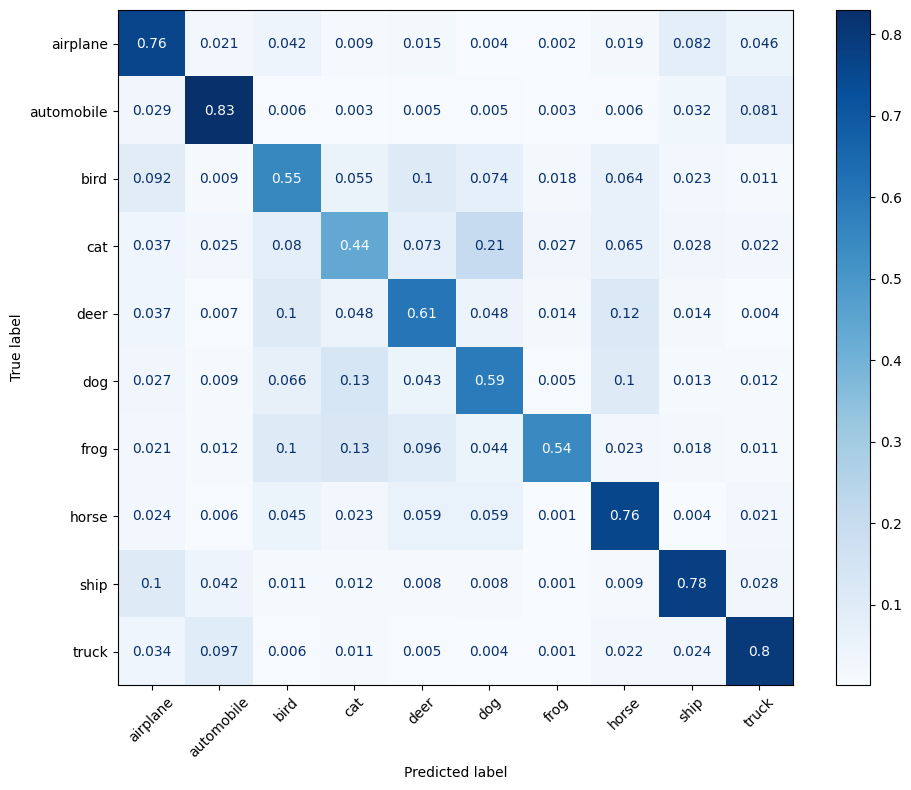

In [90]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_numpy, display_labels=classes)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.tight_layout()
plt.show()


In [94]:
from pathlib import Path

MODEL_PATH = Path("CIFAR_MODELS")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME = "cifar10_model_0.pt"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME

torch.save(obj=model_0.state_dict(),f=MODEL_SAVE_PATH)
print("Model saved successfully to the path ",MODEL_SAVE_PATH)

Model saved successfully to the path  CIFAR_MODELS\cifar10_model_0.pt


## Ways to improve the model 
 - Perform data augmentation in the dataset to avoid overfitting and underfitting
 - Do the batch normalisation in the input value to shrink the values close to mean and std
 - Choose the lr scheduler for perfect learning rate for the model 